In [7]:
# Conten below is from the preprocessing tutorial on the MNE website, since I am not necessarily doing preprocessing, this might not be necessary?

#none of the imports are in the environment so far
import pandas as pd
import numpy as np
import mne
import matplotlib.pyplot as plt
# data path might be connected to the example data that the tutorials want me to load, but since it seems to be used as a function below I am not sure if I might still need it  
from mne.datasets.eyelink import data_path
from mne.io import read_raw_eyelink
import seaborn as sns
#where do I have the following line from, doesnt work so do I need it?
#from mne.preprocessing.eyetracking import read_eyelink_calibration

# my own line:
folder_path = "/mnt/home/bielefeldt/MPIB-SRT/879-multieyetem/data_eyelink"

# no idea what the following line is supposed to do, probably is supposed to add individual data files to the general path, could probably be done better, might want to loop over the files in the folder like I did in the behav_data, BUT concatenating them might not be a good idea,
# even though I might have to concatenate them to be able to calculate means, but no I dont think I need that for the means, maybe though...

et_fpath = folder_path + "/REUNMA.asc"

raw_et = mne.io.read_raw_eyelink(et_fpath, preload=True, create_annotations=["blinks"])
#raw_et = mne.io.read_raw_eyelink(folder_path, preload=True, create_annotations=["blinks"])


info = raw_et.info
info_keys = info.keys()
print(info_keys)
raw_et.info
ch_names = info["ch_names"]
print(info["ch_names"])

Loading /mnt/home/bielefeldt/MPIB-SRT/879-multieyetem/data_eyelink/REUNMA.asc
Pixel coordinate data detected.Pass `scalings=dict(eyegaze=1e3)` when using plot method to make traces more legible.
Pupil-size area detected.


## from MNE Python Tutorial
probably useful then to use a numpy library like tried below

event_dict = {

    "auditory/left": 1,
    "auditory/right": 2,
    "visual/left": 3,
    "visual/right": 4,
    "smiley": 5,
    "buttonpress": 32,
}

Event dictionaries like this one are used when extracting epochs from continuous data; the / character in the dictionary keys allows pooling across conditions by requesting partial condition descriptors (i.e., requesting 'auditory' will select all epochs with Event IDs 1 and 2; requesting 'left' will select all epochs with Event IDs 1 and 3).


In [2]:
x_y_df = raw_et["xpos_left"]
print(x_y_df)

type(raw_et)


# # Create empty lists to store the extracted data
# xpos_left = raw_et["xpos_left"]
# ypos_left = raw_et["ypos_left"]
# xpos_right = raw_et["xpos_right"]
# ypos_right = raw_et["ypos_right"]
# blink = raw_et["xpos_left"]

# # Create empty lists to store the extracted data
# xpos_left = []
# ypos_left = []
# xpos_right = []
# ypos_right = []
# blink = []

# # Parse the data and extract it into lists
# for line in raw_et:
#     values = line.strip().split(', ')
#     xpos_left.append(int(values[0]))
#     ypos_left.append(int(values[1]))
#     xpos_right.append(int(values[2]))
#     ypos_right.append(int(values[3]))
#     blink.append(bool(values[4].lower() == 'true'))

# # Create a DataFrame from the extracted data
# eye_tracking_data = pd.DataFrame({
#     'x_left': xpos_left,
#     'y_left': ypos_left,
#     'x_right': xpos_right,
#     'y_right': ypos_right,
#     'blink': blink
# })


(array([[1154.5, 1154.5, 1152.7, ..., 1306.1, 1306.6, 1306.6]]), array([0.000000e+00, 2.000000e-03, 4.000000e-03, ..., 6.447670e+03,
       6.447672e+03, 6.447674e+03]))


mne.io.eyelink.eyelink.RawEyelink

In [3]:
## Could potentially change the sequencing/epoching, right now it is probably default, right now there seems to be a timestamp ever 2ms (0.002 seconds) - if it indeed is in seconds

# Can add the rest of the data to this manually (maybe there is a better way though)


print(ch_names)

Output: ['xpos_left', 'ypos_left', 'pupil_left', 'xpos_right', 'ypos_right', 'pupil_right', 'DIN', 'x_head', 'y_head', 'distance']

xpos_left = raw_et["xpos_left"]
ypos_left = raw_et["ypos_left"]
xpos_right = raw_et["xpos_right"]
ypos_right = raw_et["ypos_right"]
pupil_left = raw_et['pupil_left']
pupil_right = raw_et['pupil_right']

# Extract data and timestamps separately
timestamps = xpos_left[1]
xpos_left_data = xpos_left[0][0]
ypos_left_data = ypos_left[0][0]
xpos_right_data = xpos_right[0][0]
ypos_right_data = ypos_right[0][0]
pupil_left_data = pupil_left[0][0]
pupil_right_data = pupil_right[0][0]

# Create a pandas DataFrame with column name 'xpos_left' and data and timestamps as values
eyetracking_data = pd.DataFrame({'timestamps': timestamps, 'xpos_left': xpos_left_data,'ypos_left': ypos_left_data, 'xpos_right': xpos_right_data, 'ypos_right': ypos_right_data, 'pupil_left': pupil_left_data, 'pupil_right': pupil_right_data})

print(raw_et['pupil_left'])


['xpos_left', 'ypos_left', 'pupil_left', 'xpos_right', 'ypos_right', 'pupil_right', 'DIN', 'x_head', 'y_head', 'distance']
(array([[ 810.,  810.,  810., ..., 1062., 1066., 1065.]]), array([0.000000e+00, 2.000000e-03, 4.000000e-03, ..., 6.447670e+03,
       6.447672e+03, 6.447674e+03]))


## Heatmaps

In [9]:
plt.figure(figsize=(8,6))
sns.set_context('paper', font_scale=1.4)

eyetracking_mx = eyetracking_data.corr()

sns.heatmap(eyetracking_mx, annot=True, cmap='Blues')

AttributeError: module 'numpy' has no attribute 'bool'.
`np.bool` was a deprecated alias for the builtin `bool`. To avoid this error in existing code, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
The aliases was originally deprecated in NumPy 1.20; for more details and guidance see the original release note at:
    https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations

NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Using matplotlib as 2D backend.


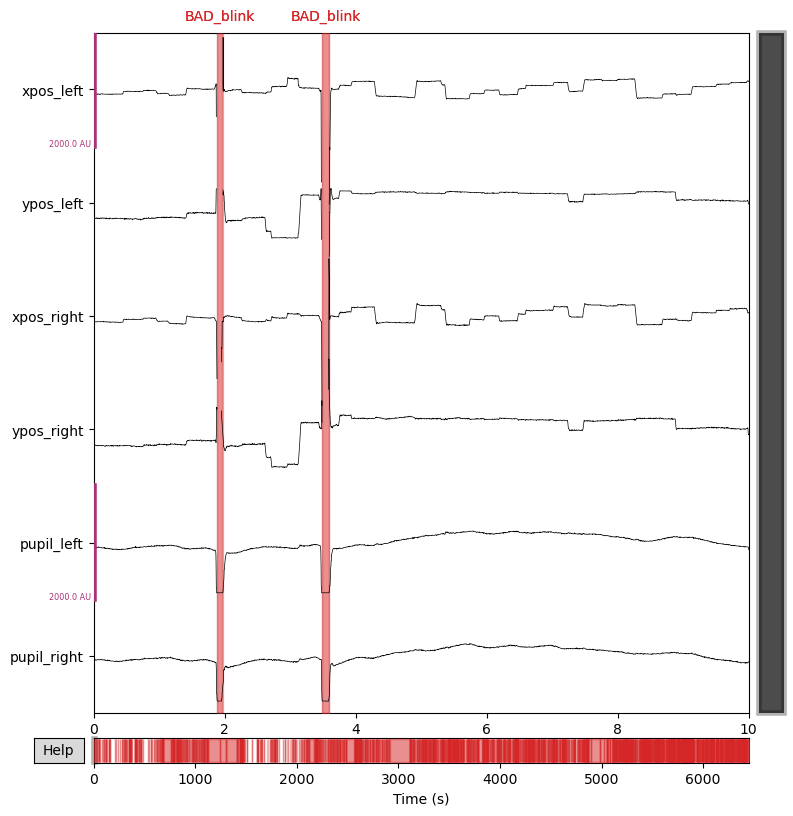

In [4]:
## Plots

# why are only two frames shown, what is the timing, what is the scaline, what is eyegaze=1e3

custom_scalings = dict(eyegaze=1e3)
raw_et.pick_types(eyetrack=True).plot(scalings=custom_scalings)

In [ ]:
## Need the general x,y coordinates (with NANs for blinks)
